# Notebook 02 - Q1: Phân tích Chuyên sâu Câu hỏi Q1 (VeDDRA & Xu hướng theo quý)
**Đề tài:** Phân tích Sự cố Bất lợi Thuốc Thú y (OpenFDA Animal & Veterinary Adverse Events) giai đoạn 2025 và Đối chiếu Xu hướng 2026 (Q1)

**Môn học:** CSC17104 – Lập trình cho Khoa học Dữ liệu  
**Nhóm thực hiện:** Global Ban  
**Thành viên phụ trách:** Đinh Công Khang  
**Phản biện chéo:** Huỳnh Tuấn Kiệt  
**Liên kết Master Hub:** [Notebook 02: Master Hub (Mục 3.3 Question Formulation & D1–D6)](02_analysis.ipynb)


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập đường dẫn gốc dự án
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.data_loader import load_processed
from src.preprocessing import log_row_count_change
from src.visualization import set_project_plot_style
set_project_plot_style()

In [2]:
# Tải dữ liệu đã qua tiền xử lý chuẩn hóa từ data/processed/clean
data = load_processed(PROJECT_ROOT / 'data' / 'processed' / 'clean')
reports = data['reports']
reactions = data['reactions']
drugs = data['drugs']
outcomes = data['outcomes']

print(f"[Data Loaded] Reports: {reports.shape}, Reactions: {reactions.shape}, Drugs: {drugs.shape}, Outcomes: {outcomes.shape}")

[Data Loaded] Reports: (93812, 53), Reactions: (267848, 8), Drugs: (173221, 31), Outcomes: (84543, 6)


---
## Câu hỏi Q1: Phản ứng VeDDRA hàng đầu & Xu hướng biến động theo quý

### Phát biểu câu hỏi và Động lực
- **Phát biểu câu hỏi:**  
  > **"Những phản ứng bất lợi (VeDDRA terms) nào chiếm tỷ trọng cao nhất ở Chó, Mèo và các loài gia súc/vật nuôi khác trong năm 2025, và xu hướng theo quý (kèm dấu hiệu mùa vụ trong phạm vi 1 năm) của các phản ứng hàng đầu này biến động như thế nào cho đến nửa đầu năm 2026 (Q1)?"**
- **Người quan tâm & Quyết định hỗ trợ (Target Users & Decisions):**
  - **Bác sĩ thú y lâm sàng:** Cần nắm bắt mô hình triệu chứng phổ biến nhất theo từng loài cụ thể để chẩn đoán phân biệt và nhận diện sớm các phản ứng bất lợi sau điều trị theo từng mùa trong năm.
  - **Cơ quan quản lý (FDA CVM) & Nhà sản xuất thuốc:** Cần giám sát tín hiệu an toàn thời gian thực để phát hiện các đợt bùng phát bất thường (outbreaks) hoặc sự gia tăng đột biến của phản ứng phụ theo quý.
- **Tiêu chí độ sâu áp dụng (Mục 3.3):**
  - `D1` (Combining data): Nối bảng báo cáo cha `reports` với bảng triệu chứng lâm sàng con `reactions` theo khóa `unique_aer_id_number` (kiểm tra số dòng trước/sau và tỷ lệ khớp).
  - `D2` (Reshaping & time): Resample dữ liệu theo quý (2025 Q1 — 2026 Q1), xoay bảng (pivot table) tần suất phản ứng theo thời gian và tính tỷ lệ biến động qua từng kỳ.
  - `D5` (Quantifying uncertainty): Ước lượng khoảng tin cậy 95% Bootstrap cho tỷ lệ phản ứng theo quý và thực hiện kiểm định $\chi^2$ về tính đồng nhất phân bố mùa vụ.

### 1. Tiền xử lý dữ liệu cho Q1

1. **Bước 1.1 — Lọc quần thể thú y mục tiêu:**
   - Dữ liệu openFDA Adverse Events bao gồm cả một số ca báo cáo trên người (`species == "Human"`). Do đề tài tập trung vào sức khỏe vật nuôi, Q1 loại bỏ toàn bộ bản ghi `Human` và ghi log số dòng trước/sau.
   - Bước này được tái kiểm chứng dù đầu vào đã là bảng sạch từ NB01 nhưng Q1 không giả định ngầm rằng upstream đã đúng.
   - Tiếp theo, loại báo cáo có `type_of_information` chứa `With no Adverse Events` (lỗi sản phẩm không kèm phản ứng bất lợi) và loại báo cáo `Other` có `species` là placeholder/`Unknown`, vì câu hỏi chỉ xét adverse event ở các loài được xác định. Mỗi bước đều có log số dòng trước/sau.

2. **Bước 1.2 — Kết nối đa bảng theo chiều sâu (Tiêu chí D1 — Combining data):**
   - Nối bảng báo cáo cha `reports` với bảng triệu chứng con `reactions` qua khóa `unique_aer_id_number` (Inner Join), với suffix phân biệt nguồn cột.
   - Kiểm tra zero orphan keys, số báo cáo có ít nhất một reaction và số báo cáo không có reaction (chủ yếu nhóm *Product Defect*).
   - `quarter` của `reports` được dùng để làm trục thời gian và số dòng lệch với `quarter` của `reactions` được in ra để đối chiếu.

3. **Bước 1.3 — Giới hạn phạm vi thời gian nghiên cứu (5 quý liên tiếp):**
   - Lọc các bản ghi thuộc 5 phân vùng quý từ `2025q1` đến `2026q1`.
   - Làm sạch `veddra_term_name` và `veddra_term_code` bằng `PLACEHOLDER_RE` (bao phủ cả `MSK`, `Not given`, `No information supplied`, `*(Unknown)`…), không chỉ dùng tập token rỗng thủ công.

4. **Bước 1.4 — Phân loại nhóm loài & Khử trùng lặp cấp (Ca bệnh, Mã term, Quý) (Tiêu chí D2):**
   - Ánh xạ loài thành 3 nhóm: **Chó (`Dog`)**, **Mèo (`Cat`)** và **Các loài khác (`Other`)**.
   - Gán một tên đại diện (canonical) cho mỗi `veddra_term_code` vì có 12 mã ánh xạ tới nhiều tên hiển thị.
   - Khử trùng lặp theo `(unique_aer_id_number, veddra_term_code, quarter)` để mỗi ca bệnh chỉ đóng góp tối đa 1 lần cho cùng một mã VeDDRA trong một quý.
   - Kết quả: `q1_long` (alias `q1_clean`) dùng cho prevalence/bootstrap; `q1_report` (1 báo cáo = 1 `dominant_term`) dùng cho kiểm định χ².

In [3]:
from src.preprocessing import PLACEHOLDER_RE

try:
    from IPython.display import display as _ipython_display
except Exception:
    _ipython_display = None


def display(obj, *args, **kwargs):
    """Rich display trong Jupyter; fallback print khi execute ngoài kernel."""
    if _ipython_display is not None:
        return _ipython_display(obj, *args, **kwargs)
    if isinstance(obj, pd.DataFrame):
        print(obj.to_string())
    else:
        print(obj)


KEY = "unique_aer_id_number"
QUARTERS = ["2025q1", "2025q2", "2025q3", "2025q4", "2026q1"]
QUARTER_LABELS = ["2025 Q1", "2025 Q2", "2025 Q3", "2025 Q4", "2026 Q1"]
GROUP_ORDER = ["Dog", "Cat", "Other"]


def is_placeholder(value) -> bool:
    if pd.isna(value):
        return True
    text = str(value).strip()
    if not text or text.lower() in {"nan", "none", "<na>", "null"}:
        return True
    return bool(PLACEHOLDER_RE.match(text))


# Audit tối thiểu ngay trước khi dựng analysis dataset
audit_summary = pd.DataFrame({
    "check": [
        "reports rows", "reactions rows", "duplicate report keys",
        "orphan reaction keys", "missing term labels", "missing term codes",
        "codes with >1 label", "labels with >1 code",
    ],
    "value": [
        len(reports), len(reactions), int(reports[KEY].duplicated().sum()),
        int((~reactions[KEY].isin(reports[KEY])).sum()),
        int(reactions["veddra_term_name"].map(is_placeholder).sum()),
        int(reactions["veddra_term_code"].map(is_placeholder).sum()),
        int((reactions.dropna(subset=["veddra_term_code", "veddra_term_name"])
             .groupby("veddra_term_code")["veddra_term_name"].nunique() > 1).sum()),
        int((reactions.dropna(subset=["veddra_term_code", "veddra_term_name"])
             .groupby("veddra_term_name")["veddra_term_code"].nunique() > 1).sum()),
    ],
})
display(audit_summary)

# ===== Tiền xử lý dữ liệu phục vụ câu hỏi Q1 =====
audit_log = []


def _audit_step(name: str, before: int, after: int, note: str) -> None:
    log_row_count_change(name, before, after, note)
    audit_log.append({
        "step": name,
        "rows_before": before,
        "rows_after": after,
        "delta": after - before,
        "note": note,
    })


def _clean_str(series: pd.Series) -> pd.Series:
    out = series.astype("string").str.strip()
    out = out.mask(out.isna() | out.eq(""))
    out = out.mask(out.str.lower().isin(["nan", "none", "<na>", "null"]))
    return out.mask(out.map(lambda v: is_placeholder(v) if pd.notna(v) else True))


# 1.1 Select columns
rep_cols = [c for c in [KEY, "quarter", "species", "species_group",
                        "type_of_information", "primary_reporter"] if c in reports.columns]
rea_cols = [c for c in [KEY, "quarter", "veddra_term_code", "veddra_term_name",
                        "accuracy"] if c in reactions.columns]

rep = reports[rep_cols].copy()
rea = reactions[rea_cols].copy()
_audit_step("Q1_01_select_report_cols", len(reports), len(rep), "Chọn cột báo cáo cần thiết")
_audit_step("Q1_02_select_reaction_cols", len(reactions), len(rea), "Chọn cột reaction cần thiết")

for col in rep.columns:
    if col != KEY:
        rep[col] = _clean_str(rep[col])
for col in rea.columns:
    if col != KEY:
        rea[col] = _clean_str(rea[col])

if "species_group" not in rep.columns:
    rep["species_group"] = (rep["species"].fillna("").str.lower()
                            .map({"dog": "Dog", "cat": "Cat"}).fillna("Other"))
    print("[Q1] species_group được suy từ species vì bảng đầu vào không có cột này")

# 1.2 Loại ca Humans, báo cáo không có adverse events và Other không rõ loài
before = len(rep)
human_mask = rep["species"].fillna("").str.lower().eq("human")
rep = rep.loc[~human_mask].copy()
_audit_step("Q1_03_drop_human", before, len(rep), "Giữ đúng quần thể thú y")

before = len(rep)
no_ae = rep["type_of_information"].fillna("").str.contains(
    "With no Adverse Events", case=False, regex=False)
rep = rep.loc[~no_ae].copy()
_audit_step("Q1_03b_drop_no_adverse_event", before, len(rep),
            "Loại báo cáo Product Defect có nhãn 'With no Adverse Events'")

before = len(rep)
unknown_other = rep["species_group"].eq("Other") & rep["species"].isna()
rep = rep.loc[~unknown_other].copy()
_audit_step("Q1_03c_drop_unknown_other", before, len(rep),
            "Chỉ giữ nhóm Other có loài được xác định")

# 1.3 Join D1
before = len(rea)
joined = rea.merge(rep, on=KEY, how="inner", suffixes=("_reaction", "_report"))
_audit_step("Q1_04_join_reactions_reports", before, len(joined),
            "Inner join reaction x report theo unique_aer_id_number")

n_rep = rep[KEY].nunique()
n_matched = joined[KEY].nunique()
unmatched = n_rep - n_matched
print(f"[Q1 join] báo cáo có ít nhất một reaction: {n_matched:,}/{n_rep:,} "
      f"({n_matched / n_rep * 100:.2f}%) | unmatched = {unmatched:,}")

# 1.4 Trục thời gian lấy từ report
mismatch_q = int((joined["quarter_reaction"].fillna("") != joined["quarter_report"].fillna("")).sum())
joined["quarter"] = joined["quarter_report"]
print(f"[Q1 quarter audit] khác biệt quarter reaction vs report: {mismatch_q:,} dòng "
      f"→ dùng quarter từ reports làm trục thời gian")

# 1.5 Lọc quý
before = len(joined)
joined = joined.loc[joined["quarter"].isin(QUARTERS)].copy()
_audit_step("Q1_05_filter_quarters", before, len(joined), "Giữ 2025q1–2026q1")

# 1.6 Term/code hợp lệ
before = len(joined)
valid_term = joined["veddra_term_code"].notna() & joined["veddra_term_name"].notna()
joined = joined.loc[valid_term].copy()
_audit_step("Q1_06_valid_term_code", before, len(joined), "Loại term/code thiếu hoặc placeholder")

# 1.7 Chuẩn hóa nhóm loài
joined["species_group"] = joined["species_group"].where(
    joined["species_group"].isin(GROUP_ORDER), "Other"
)

# 1.8 Tên đại diện cho mỗi mã VeDDRA
code_to_name = (
    joined[["veddra_term_code", "veddra_term_name"]]
    .dropna()
    .groupby("veddra_term_code")["veddra_term_name"]
    .agg(lambda s: s.value_counts().idxmax())
    .rename("term_canonical")
)
joined = joined.join(code_to_name, on="veddra_term_code")
joined["veddra_term_name"] = joined["term_canonical"].fillna(joined["veddra_term_name"])
joined = joined.drop(columns="term_canonical")

# 1.9 Dedup theo báo cáo–mã term–quý
before = len(joined)
q1_long = (joined
           .drop_duplicates(subset=[KEY, "veddra_term_code", "quarter"], keep="first")
           .reset_index(drop=True))
_audit_step("Q1_07_dedup_report_term_quarter", before, len(q1_long),
            "Mỗi báo cáo đóng góp tối đa 1 lần cho một mã VeDDRA trong một quý")

print(f"\n[Q1 dataset] q1_long = {len(q1_long):,} dòng | "
      f"{q1_long[KEY].nunique():,} báo cáo | "
      f"{q1_long['veddra_term_code'].nunique():,} mã VeDDRA")
display(pd.DataFrame(audit_log))

print(f"\n[Q1 Tiền xử lý hoàn tất] Dữ liệu sạch cho Q1: {len(q1_long):,} dòng ({q1_long[KEY].nunique():,} ca báo cáo duy nhất).")

,check,value
0,reports rows,93812
1,reactions rows,267848
2,duplicate report keys,0
3,orphan reaction keys,0
4,missing term labels,0
5,missing term codes,0
6,codes with >1 label,12
7,labels with >1 code,0


[Q1_01_select_report_cols] Rows: 93,812 -> 93,812 (Change: +0 | +0.00%) | Reason: Chọn cột báo cáo cần thiết
[Q1_02_select_reaction_cols] Rows: 267,848 -> 267,848 (Change: +0 | +0.00%) | Reason: Chọn cột reaction cần thiết
[Q1_03_drop_human] Rows: 93,812 -> 93,812 (Change: +0 | +0.00%) | Reason: Giữ đúng quần thể thú y
[Q1_03b_drop_no_adverse_event] Rows: 93,812 -> 84,093 (Change: -9,719 | -10.36%) | Reason: Loại báo cáo Product Defect có nhãn 'With no Adverse Events'
[Q1_03c_drop_unknown_other] Rows: 84,093 -> 84,035 (Change: -58 | -0.07%) | Reason: Chỉ giữ nhóm Other có loài được xác định
[Q1_04_join_reactions_reports] Rows: 267,848 -> 253,097 (Change: -14,751 | -5.51%) | Reason: Inner join reaction x report theo unique_aer_id_number
[Q1 join] báo cáo có ít nhất một reaction: 84,035/84,035 (100.00%) | unmatched = 0
[Q1 quarter audit] khác biệt quarter reaction vs report: 0 dòng → dùng quarter từ reports làm trục thời gian
[Q1_05_filter_quarters] Rows: 253,097 -> 253,097 (Change: +0 |

,step,rows_before,rows_after,delta,note
0,Q1_01_select_report_cols,93812,93812,0,Chọn cột báo cáo cần thiết
1,Q1_02_select_reaction_cols,267848,267848,0,Chọn cột reaction cần thiết
2,Q1_03_drop_human,93812,93812,0,Giữ đúng quần thể thú y
3,Q1_03b_drop_no_adverse_event,93812,84093,-9719,Loại báo cáo Product Defect có nhãn 'With no A...
4,Q1_03c_drop_unknown_other,84093,84035,-58,Chỉ giữ nhóm Other có loài được xác định
5,Q1_04_join_reactions_reports,267848,253097,-14751,Inner join reaction x report theo unique_aer_i...
6,Q1_05_filter_quarters,253097,253097,0,Giữ 2025q1–2026q1
7,Q1_06_valid_term_code,253097,253097,0,Loại term/code thiếu hoặc placeholder
8,Q1_07_dedup_report_term_quarter,253097,253097,0,Mỗi báo cáo đóng góp tối đa 1 lần cho một mã V...



[Q1 Tiền xử lý hoàn tất] Dữ liệu sạch cho Q1: 253,097 dòng (84,035 ca báo cáo duy nhất).


### 2. Phương pháp phân tích

**Lựa chọn phương pháp:** Phương pháp 1 là phương pháp chính để trả lời trực tiếp câu hỏi về VeDDRA chiếm tỷ trọng cao nhất theo từng loài. Phương pháp 2 và 3 được kết hợp để mô tả xu hướng theo quý và định lượng uncertainty.

Phương pháp được chọn bám sát **đơn vị quan sát là báo cáo** (`unique_aer_id_number`), không phải dòng reaction.

- **Phương pháp 1:** Xếp hạng Top 10 phản ứng VeDDRA có tần suất xuất hiện cao nhất, phân tầng độc lập cho Chó, Mèo và các loài khác trong năm 2025. Tỷ trọng được tính bằng `số báo cáo duy nhất có term / số báo cáo duy nhất trong nhóm loài × năm`.
- **Phương pháp 2:** Tính tỷ lệ phần trăm của từng phản ứng trong tổng số báo cáo của từng quý từ 2025 Q1 đến 2026 Q1, xoay bảng (pivot) theo quý và tính chênh lệch cùng kỳ `diff_pp = share(2026Q1) − share(2025Q1)`.
- **Phương pháp 3:** Ước lượng khoảng tin cậy 95% Bootstrap cho tỷ lệ phản ứng hàng đầu theo từng quý bằng cách resample theo **báo cáo** (1.000 lần, seed = 42), đồng thời kiểm định $\chi^2$ trên `q1_report` kèm Cramér's V. Riêng nhóm `Other` chỉ dùng 6 term hàng đầu trong bảng $\chi^2$ để mọi ô kỳ vọng $\geq 5$. Độ vững được kiểm tra bằng cách loại báo cáo `Product Defect` và đổi `K = 10 → 5`.

In [4]:
# ===== 2. Xếp hạng, tỷ trọng, bootstrap, kiểm định =====
q1_2025 = q1_long.loc[q1_long["quarter"].str.startswith("2025")].copy()

K = 10
TRACK_K = 5
CHI_K_BY_GROUP = {"Dog": 8, "Cat": 8, "Other": 6}
rng = np.random.default_rng(42)

# 2.1 Denominator & numerator ở cấp báo cáo
denominator = (q1_long
               .groupby(["species_group", "quarter"], observed=True)[KEY]
               .nunique().rename("n_reports").reset_index())
numerator = (q1_long
             .groupby(["species_group", "quarter", "veddra_term_name"], observed=True)[KEY]
             .nunique().rename("n_reports_with_term").reset_index())

term_prevalence = numerator.merge(denominator, on=["species_group", "quarter"], how="left")
term_prevalence["share_pct"] = (term_prevalence["n_reports_with_term"]
                                / term_prevalence["n_reports"] * 100)

# 2.2 Top-K theo loài, dùng dữ liệu năm 2025
top_terms_by_group: dict[str, list[str]] = {}
top_term_stats: list[dict] = []

for group in GROUP_ORDER:
    base = q1_2025[q1_2025["species_group"].eq(group)]
    n_group = base[KEY].nunique()
    counts = (base.groupby("veddra_term_name", observed=True)[KEY]
              .nunique().sort_values(ascending=False))
    top_terms_by_group[group] = counts.head(K).index.tolist()
    for rank, (term, n_term) in enumerate(counts.head(K).items(), start=1):
        top_term_stats.append({
            "species_group": group, "rank": rank, "veddra_term_name": term,
            "n_reports_with_term": int(n_term), "n_reports_group": int(n_group),
            "share_2025_pct": n_term / n_group * 100 if n_group else np.nan,
        })

top_terms_df = pd.DataFrame(top_term_stats)
print(f"[Top-{K}] số báo cáo theo nhóm loài (2025): "
      + ", ".join(f"{g}={q1_2025[q1_2025.species_group.eq(g)][KEY].nunique():,}" for g in GROUP_ORDER))
display(top_terms_df[top_terms_df["rank"] <= 5].reset_index(drop=True))

# 2.2b Bảng một báo cáo – một dominant term, dùng cho kiểm định không đếm trùng
rank_map = {(group, term): i
            for group, terms in top_terms_by_group.items()
            for i, term in enumerate(terms[:CHI_K_BY_GROUP[group]])}
q1_report = q1_2025[[KEY, "quarter", "species_group", "veddra_term_name"]].copy()
q1_report["_rank"] = [
    rank_map.get((group, term), CHI_K_BY_GROUP[group])
    for group, term in zip(q1_report["species_group"], q1_report["veddra_term_name"])
]
q1_report = (q1_report
             .sort_values([KEY, "_rank", "veddra_term_name"], kind="stable")
             .drop_duplicates(subset=[KEY], keep="first")
             .rename(columns={"veddra_term_name": "dominant_term"})
             .drop(columns="_rank")
             .reset_index(drop=True))
print(f"[Report-level] q1_report = {len(q1_report):,} dòng "
      f"(1 báo cáo = 1 dominant term)")

# 2.3 Pivot tỷ trọng theo quý
tracked_terms = pd.concat([
    term_prevalence[(term_prevalence["species_group"].eq(group))
                    & (term_prevalence["veddra_term_name"].isin(terms))].copy()
    for group, terms in top_terms_by_group.items()
], ignore_index=True)

pivot_share = (tracked_terms
               .pivot_table(index=["species_group", "veddra_term_name"],
                            columns="quarter", values="share_pct",
                            aggfunc="first", observed=True)
               .reindex(columns=QUARTERS))
print(f"[Pivot] shape = {pivot_share.shape} (nhóm loài × term) × 5 quý")

# 2.4 Bootstrap CI theo báo cáo
def bootstrap_share_ci(frame: pd.DataFrame, term: str,
                       n_boot: int = 1000, alpha: float = 0.05,
                       random_generator: np.random.Generator | None = None):
    sub = frame.loc[frame["veddra_term_name"].eq(term), KEY]
    if sub.empty:
        return np.nan, np.nan, np.nan, 0

    group_ids = frame[KEY].drop_duplicates().to_numpy()
    n = len(group_ids)
    if n == 0:
        return np.nan, np.nan, np.nan, 0

    has_term = set(sub.unique())
    y = np.isin(group_ids, list(has_term)).astype(np.int8)
    point = float(y.mean())

    if random_generator is None:
        random_generator = np.random.default_rng(42)
    if point <= 0 or point >= 1:
        draws = np.full(n_boot, point)
    else:
        draws = random_generator.binomial(n, point, size=n_boot) / n

    lo, hi = np.percentile(draws, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return point * 100, lo * 100, hi * 100, n


ci_rows = []
for group in GROUP_ORDER:
    for quarter in QUARTERS:
        sub = q1_long[(q1_long["species_group"].eq(group))
                      & (q1_long["quarter"].eq(quarter))]
        for term in top_terms_by_group[group][:TRACK_K]:
            point, lo, hi, n_reports = bootstrap_share_ci(
                sub, term, n_boot=1000, random_generator=rng
            )
            ci_rows.append({
                "species_group": group, "quarter": quarter,
                "veddra_term_name": term, "share_pct": point,
                "ci_low": lo, "ci_high": hi, "n_reports": n_reports,
            })
ci_df = pd.DataFrame(ci_rows)
print(f"[Bootstrap] {len(ci_df):,} khoảng tin cậy (top-{TRACK_K}/nhóm × 5 quý)")
display(ci_df.head(9).reset_index(drop=True))

# 2.5 So sánh cùng kỳ 2026Q1 vs 2025Q1
def _share_of(group: str, term: str, quarter: str) -> float:
    hit = term_prevalence[(term_prevalence["species_group"].eq(group))
                          & (term_prevalence["veddra_term_name"].eq(term))
                          & (term_prevalence["quarter"].eq(quarter))]
    return float(hit["share_pct"].iat[0]) if len(hit) else 0.0


yoy_rows = []
for group in GROUP_ORDER:
    for term in top_terms_by_group[group]:
        s25 = _share_of(group, term, "2025q1")
        s26 = _share_of(group, term, "2026q1")
        yoy_rows.append({
            "species_group": group, "veddra_term_name": term,
            "share_2025Q1": s25, "share_2026Q1": s26, "diff_pp": s26 - s25,
        })
yoy_df = pd.DataFrame(yoy_rows)
for group in GROUP_ORDER:
    sub = yoy_df[yoy_df["species_group"].eq(group)].copy()
    sub["abs_diff"] = sub["diff_pp"].abs()
    top_up = sub.nlargest(2, "diff_pp")
    top_down = sub.nsmallest(2, "diff_pp")
    print(f"\n[YoY {group}] tăng mạnh nhất:")
    display(top_up[["veddra_term_name", "share_2025Q1", "share_2026Q1", "diff_pp"]]
            .reset_index(drop=True))
    print(f"[YoY {group}] giảm mạnh nhất:")
    display(top_down[["veddra_term_name", "share_2025Q1", "share_2026Q1", "diff_pp"]]
            .reset_index(drop=True))

# 2.6 Kiểm định χ² + Cramér's V
def cramers_v(chi2: float, n: int, rows: int, cols: int) -> float:
    denom = n * min(rows - 1, cols - 1)
    return float(np.sqrt(chi2 / denom)) if denom > 0 else np.nan


chi_rows: list[dict] = []
for group in GROUP_ORDER:
    terms = top_terms_by_group[group][:CHI_K_BY_GROUP[group]]
    sub = q1_2025[q1_2025["species_group"].eq(group)].copy()

    # Bảng chính: dùng q1_report (mỗi báo cáo chỉ góp 1 ô trong bảng)
    rep = q1_report[q1_report["species_group"].eq(group)].copy()
    rep["term_group"] = np.where(rep["dominant_term"].isin(terms),
                                 rep["dominant_term"], "Other terms")
    ct = (pd.crosstab(rep["term_group"], rep["quarter"])
          .reindex(columns=QUARTERS[:4], fill_value=0))
    chi2, p_value, dof, expected = stats.chi2_contingency(ct)
    chi_rows.append({
        "species_group": group, "chi2": chi2, "dof": dof, "p_value": p_value,
        "cramers_v": cramers_v(chi2, int(ct.values.sum()), *ct.shape),
        "n_reports": int(ct.values.sum()), "min_expected": float(expected.min()),
        "basis": "one_report_one_term",
    })

    # Bảng kiểm tra nhanh theo từng cặp báo cáo-term (dễ bị phình mẫu)
    sub["term_group"] = np.where(sub["veddra_term_name"].isin(terms),
                                 sub["veddra_term_name"], "Other terms")
    ct_rows = (pd.crosstab(sub["term_group"], sub["quarter"])
               .reindex(columns=QUARTERS[:4], fill_value=0))
    chi2_r, p_r, dof_r, exp_r = stats.chi2_contingency(ct_rows)
    chi_rows.append({
        "species_group": group, "chi2": chi2_r, "dof": dof_r, "p_value": p_r,
        "cramers_v": cramers_v(chi2_r, int(ct_rows.values.sum()), *ct_rows.shape),
        "n_reports": int(ct_rows.values.sum()), "min_expected": float(exp_r.min()),
        "basis": "report_term_pairs",
    })

all_chi_df = pd.DataFrame(chi_rows)
chi_df = (all_chi_df[all_chi_df["basis"].eq("one_report_one_term")]
          .drop(columns="basis").reset_index(drop=True))
chi_df_screening = (all_chi_df[all_chi_df["basis"].eq("report_term_pairs")]
                    .drop(columns="basis").reset_index(drop=True))

print("\n[Chi-square] bảng chính — một báo cáo gán một term (2025 Q1–Q4):")
display(chi_df)
print("[Chi-square] bảng kiểm tra nhanh theo cặp báo cáo–term:")
display(chi_df_screening)

# 2.7 Độ nhạy: loại Product Defect & đổi K
def share_over_period(frame: pd.DataFrame, group: str, term: str) -> float:
    sub = frame[frame["species_group"].eq(group)]
    denom = sub[KEY].nunique()
    n_term = sub.loc[sub["veddra_term_name"].eq(term), KEY].nunique()
    return n_term / denom * 100 if denom else np.nan


def first_term(frame: pd.DataFrame, group: str, k: int = 1) -> tuple[str, float]:
    sub = frame[frame["species_group"].eq(group)]
    counts = sub.groupby("veddra_term_name", observed=True)[KEY].nunique().sort_values(ascending=False)
    term = counts.index[0]
    return term, share_over_period(frame, group, term)


no_defect = q1_2025.loc[~q1_2025["type_of_information"].fillna("")
                        .str.contains("Product Defect", case=False, regex=False)].copy()

robustness_rows = []
for group in GROUP_ORDER:
    base_term, base_share = first_term(q1_2025, group)
    alt_term, alt_share = first_term(no_defect, group)
    robustness_rows.append({
        "species_group": group,
        "top1_all_2025": base_term, "share_all_pct": base_share,
        "top1_no_product_defect": alt_term, "share_no_defect_pct": alt_share,
        "top1_changed": base_term != alt_term,
        "n_all": int(q1_2025[q1_2025["species_group"].eq(group)][KEY].nunique()),
        "n_no_defect": int(no_defect[no_defect["species_group"].eq(group)][KEY].nunique()),
    })
robustness_df = pd.DataFrame(robustness_rows)

k_sensitivity = pd.DataFrame([
    {"species_group": group, "K": 5, "top_terms": " | ".join(top_terms_by_group[group][:5])}
    for group in GROUP_ORDER
] + [
    {"species_group": group, "K": 10, "top_terms": " | ".join(top_terms_by_group[group])}
    for group in GROUP_ORDER
])

print("\n[Robustness] Top-1 trước/sau khi loại Product Defect:")
display(robustness_df)
print("[Robustness] danh sách Top term theo K:")
display(k_sensitivity)

# 2.8 Tóm tắt số liệu chính để điền vào phần kết luận
print("\n" + "=" * 78)
print("[KEY NUMBERS] Top-1 VeDDRA theo nhóm loài, năm 2025")
for group in GROUP_ORDER:
    term = top_terms_by_group[group][0]
    denom = q1_2025[q1_2025["species_group"].eq(group)][KEY].nunique()
    count = q1_2025[(q1_2025["species_group"].eq(group))
                    & (q1_2025["veddra_term_name"].eq(term))][KEY].nunique()
    print(f"  {group}: {term} — {count:,}/{denom:,} = {count / denom * 100:.2f}%")

print("\n[KEY NUMBERS] Bootstrap 95% CI của Top-1 tại 2026 Q1")
for group in GROUP_ORDER:
    term = top_terms_by_group[group][0]
    hit = ci_df[(ci_df["species_group"].eq(group))
                & (ci_df["quarter"].eq("2026q1"))
                & (ci_df["veddra_term_name"].eq(term))]
    if len(hit):
        r = hit.iloc[0]
        print(f"  {group}: {term} — {r['share_pct']:.2f}% "
              f"[{r['ci_low']:.2f}%, {r['ci_high']:.2f}%], n={r['n_reports']:,}")

print("\n[KEY NUMBERS] χ² (bảng chính)")
for _, r in chi_df.iterrows():
    print(f"  {r['species_group']}: chi2={r['chi2']:.1f}, dof={r['dof']}, "
          f"p={r['p_value']:.3e}, V={r['cramers_v']:.4f}, min_expected={r['min_expected']:.1f}")
print("=" * 78)

# Alias theo tên biến từng dùng trong template/master hub
rates = term_prevalence
quarter_order = QUARTERS
quarter_label = QUARTER_LABELS

[Top-10] số báo cáo theo nhóm loài (2025): Dog=54,119, Cat=12,660, Other=1,814


,species_group,rank,veddra_term_name,n_reports_with_term,n_reports_group,share_2025_pct
0,Dog,1,Vomiting,6981,54119,12.899351
1,Dog,2,Lack of efficacy (endoparasite) - heartworm,5664,54119,10.465825
2,Dog,3,Lethargy (see also Central nervous system depr...,4448,54119,8.218925
3,Dog,4,Lack of efficacy (endoparasite) - hookworm,4412,54119,8.152405
4,Dog,5,Lack of efficacy (ectoparasite) - flea,4230,54119,7.816109
5,Cat,1,Lethargy (see also Central nervous system depr...,1504,12660,11.879937
6,Cat,2,Lack of efficacy - NOS,1259,12660,9.944708
7,Cat,3,Lack of efficacy (ectoparasite) - flea,1254,12660,9.905213
8,Cat,4,Vomiting,1224,12660,9.668246
9,Cat,5,Weight loss,1183,12660,9.344392


[Report-level] q1_report = 68,593 dòng (1 báo cáo = 1 dominant term)
[Pivot] shape = (30, 5) (nhóm loài × term) × 5 quý
[Bootstrap] 75 khoảng tin cậy (top-5/nhóm × 5 quý)


,species_group,quarter,veddra_term_name,share_pct,ci_low,ci_high,n_reports
0,Dog,2025q1,Vomiting,11.782397,11.207430,12.419505,11305
1,Dog,2025q1,Lack of efficacy (endoparasite) - heartworm,11.552410,10.941840,12.136444,11305
2,Dog,2025q1,Lethargy (see also Central nervous system depr...,8.934100,8.455993,9.438302,11305
3,Dog,2025q1,Lack of efficacy (endoparasite) - hookworm,6.130031,5.661212,6.563467,11305
4,Dog,2025q1,Lack of efficacy (ectoparasite) - flea,3.334808,3.016143,3.662318,11305
5,Dog,2025q2,Vomiting,14.362554,13.837325,14.900429,15617
6,Dog,2025q2,Lack of efficacy (endoparasite) - heartworm,9.540885,9.067042,9.989275,15617
7,Dog,2025q2,Lethargy (see also Central nervous system depr...,8.445924,7.984728,8.906960,15617
8,Dog,2025q2,Lack of efficacy (endoparasite) - hookworm,9.035026,8.593040,9.477012,15617



[YoY Dog] tăng mạnh nhất:


,veddra_term_name,share_2025Q1,share_2026Q1,diff_pp
0,Lack of efficacy (ectoparasite) - flea,3.334808,8.152537,4.817729
1,Lack of efficacy (endoparasite) - hookworm,6.130031,7.026035,0.896004


... (15 outputs left out)

,species_group,top1_all_2025,share_all_pct,top1_no_product_defect,share_no_defect_pct,top1_changed,n_all,n_no_defect
0,Dog,Vomiting,12.899351,Vomiting,12.839792,False,54119,53599
1,Cat,Lethargy (see also Central nervous system depr...,11.879937,Lethargy (see also Central nervous system depr...,11.902087,False,12660,12460
2,Other,Lack of efficacy - NOS,32.855568,Lack of efficacy - NOS,33.221100,False,1814,1782


[Robustness] danh sách Top term theo K:


,species_group,K,top_terms
0,Dog,5,Vomiting | Lack of efficacy (endoparasite) - h...
1,Cat,5,Lethargy (see also Central nervous system depr...
2,Other,5,Lack of efficacy - NOS | Death | Necropsy perf...
3,Dog,10,Vomiting | Lack of efficacy (endoparasite) - h...
4,Cat,10,Lethargy (see also Central nervous system depr...
5,Other,10,Lack of efficacy - NOS | Death | Necropsy perf...



[KEY NUMBERS] Top-1 VeDDRA theo nhóm loài, năm 2025
  Dog: Vomiting — 6,981/54,119 = 12.90%
  Cat: Lethargy (see also Central nervous system depression in Neurological) — 1,504/12,660 = 11.88%
  Other: Lack of efficacy - NOS — 596/1,814 = 32.86%

[KEY NUMBERS] Bootstrap 95% CI của Top-1 tại 2026 Q1
  Dog: Vomiting — 12.56% [11.97%, 13.13%], n=11,984
  Cat: Lethargy (see also Central nervous system depression in Neurological) — 10.99% [9.90%, 12.11%], n=3,030
  Other: Lack of efficacy - NOS — 26.64% [22.66%, 31.31%], n=428

[KEY NUMBERS] χ² (bảng chính)
  Dog: chi2=840.0, dof=24, p=7.298e-162, V=0.0719, min_expected=384.8
  Cat: chi2=148.5, dof=24, p=6.216e-20, V=0.0625, min_expected=81.0
  Other: chi2=24.7, dof=18, p=1.327e-01, V=0.0674, min_expected=5.7


### 3. Kết quả và Trực quan hóa

- **Biểu đồ 1:** Barplot phân bố Top 8 thuật ngữ VeDDRA phổ biến nhất theo từng loài (Chó vs Mèo vs Khác), đơn vị `% báo cáo`.
- **Biểu đồ 2:** Lineplot biến thiên chuỗi thời gian 5 quý (2025 Q1 — 2026 Q1) của 4 phản ứng chủ đạo mỗi loài kèm dải tin cậy 95% (shaded confidence intervals).
- **Biểu đồ 3:** Barplot chênh lệch tỷ trọng cùng kỳ 2026 Q1 − 2025 Q1 (điểm phần trăm), phân biệt term tăng/giảm.

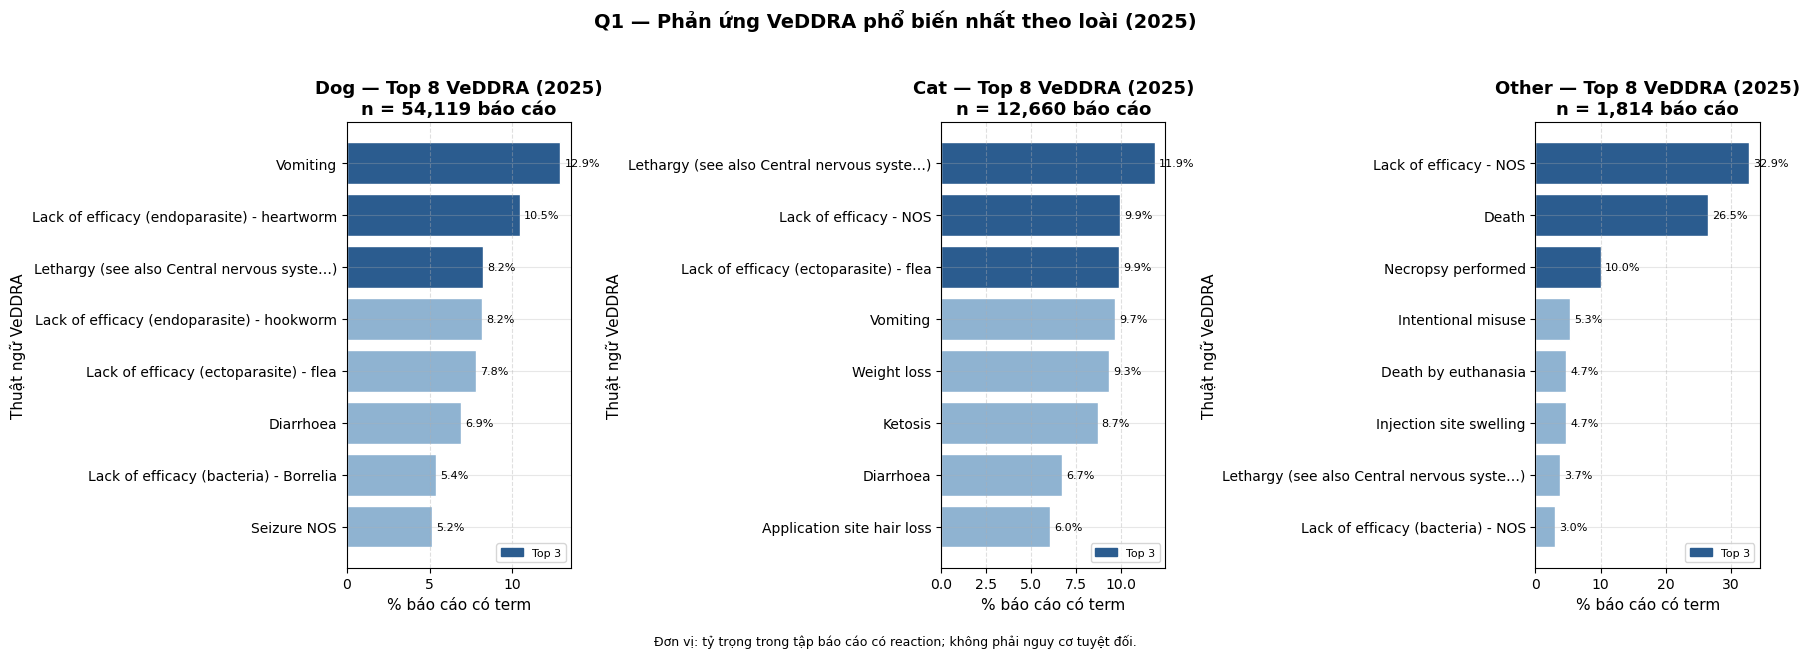

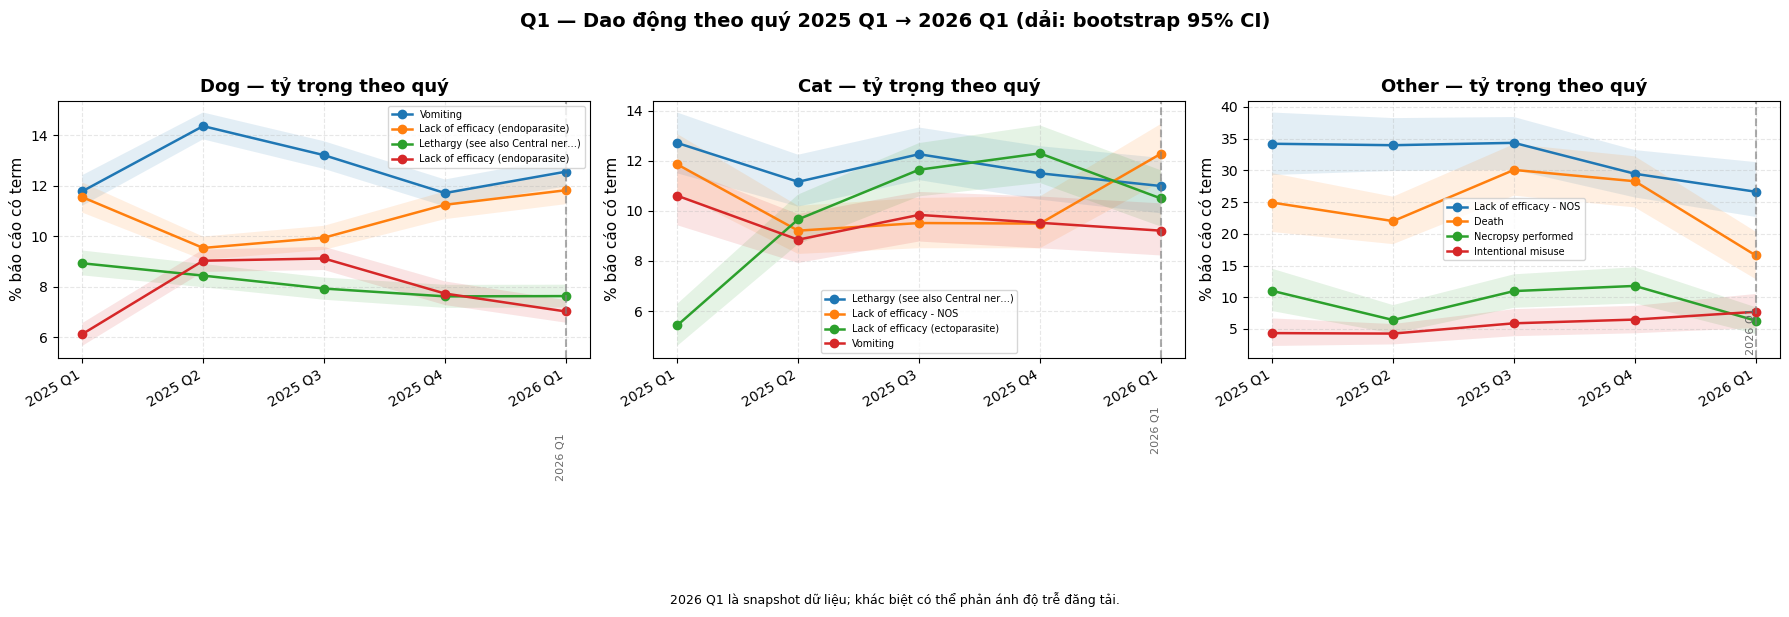

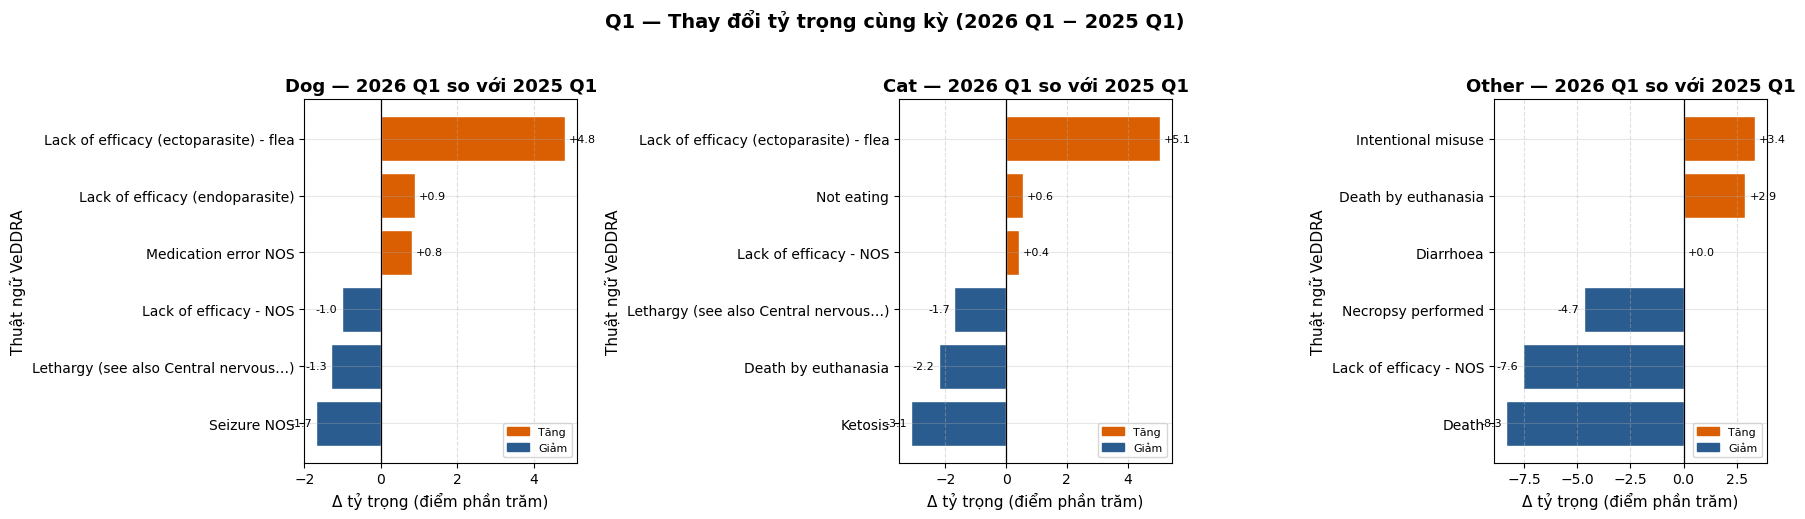

[Plots] Đã tạo 3 biểu đồ: xếp hạng theo loài, xu hướng theo quý, so sánh cùng kỳ.


In [5]:
from matplotlib.patches import Patch

# ===== 3. Trực quan hóa =====
def shorten_term(name: str, max_len: int = 42) -> str:
    text = str(name).strip()
    if len(text) <= max_len:
        return text
    if "(" in text and ")" in text:
        head, tail = text.split("(", 1)
        inside = tail.rsplit(")", 1)[0].strip()
        candidate = f"{head.strip()} ({inside})"
        if len(candidate) <= max_len:
            return candidate
        keep = max(8, max_len - len(head.strip()) - 6)
        return f"{head.strip()} ({inside[:keep].rstrip()}…)"
    return text[:max_len - 1].rstrip() + "…"


# Biểu đồ 1: Top term theo loài
fig1, axes1 = plt.subplots(1, 3, figsize=(18, 6), sharey=False)
for ax, group in zip(axes1, GROUP_ORDER):
    terms = top_terms_by_group[group][:8]
    base = q1_2025[q1_2025["species_group"].eq(group)]
    denom = base[KEY].nunique()
    counts = (base[base["veddra_term_name"].isin(terms)]
              .groupby("veddra_term_name", observed=True)[KEY]
              .nunique().reindex(terms).fillna(0))
    shares = (counts / denom * 100) if denom else counts * 0
    shares = shares.sort_values()
    colors = ["#2b5c8f" if i >= len(shares) - 3 else "#8fb3d1" for i in range(len(shares))]
    ax.barh([shorten_term(t, 44) for t in shares.index], shares.values,
            color=colors, edgecolor="white")
    ax.set_title(f"{group} — Top 8 VeDDRA (2025)\nn = {denom:,} báo cáo", fontweight="bold")
    ax.set_xlabel("% báo cáo có term")
    ax.set_ylabel("Thuật ngữ VeDDRA")
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    for bar, value in zip(ax.patches, shares.values):
        ax.annotate(f"{value:.1f}%", (value, bar.get_y() + bar.get_height() / 2),
                    xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
    ax.legend(handles=[Patch(color="#2b5c8f", label="Top 3")], loc="lower right", fontsize=8)

fig1.suptitle("Q1 — Phản ứng VeDDRA phổ biến nhất theo loài (2025)",
              fontsize=14, fontweight="bold", y=1.03)
fig1.text(0.5, -0.03,
          "Đơn vị: tỷ trọng trong tập báo cáo có reaction; không phải nguy cơ tuyệt đối.",
          ha="center", fontsize=9)
plt.tight_layout()
plt.show()

# Biểu đồ 2: Xu hướng 5 quý kèm bootstrap CI
fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5.5), sharey=False)
for ax, group in zip(axes2, GROUP_ORDER):
    for term in top_terms_by_group[group][:4]:
        s = (term_prevalence[(term_prevalence["species_group"].eq(group))
                             & (term_prevalence["veddra_term_name"].eq(term))]
             .set_index("quarter").reindex(QUARTERS))
        ax.plot(range(5), s["share_pct"].values, marker="o", linewidth=1.8,
                label=shorten_term(term, 34))
        band = (ci_df[(ci_df["species_group"].eq(group))
                      & (ci_df["veddra_term_name"].eq(term))]
                .set_index("quarter").reindex(QUARTERS))
        ax.fill_between(range(5), band["ci_low"].values, band["ci_high"].values, alpha=0.12)
    ax.axvline(4, color="gray", linestyle="--", alpha=0.65)
    ax.text(4, ax.get_ylim()[1] * 0.02, "2026 Q1", rotation=90,
            va="bottom", ha="right", fontsize=8, color="dimgray")
    ax.set_xticks(range(5))
    ax.set_xticklabels(QUARTER_LABELS, rotation=30, ha="right")
    ax.set_title(f"{group} — tỷ trọng theo quý", fontweight="bold")
    ax.set_ylabel("% báo cáo có term")
    ax.legend(fontsize=7, loc="best")
    ax.grid(linestyle="--", alpha=0.3)

fig2.suptitle("Q1 — Dao động theo quý 2025 Q1 → 2026 Q1 (dải: bootstrap 95% CI)",
              fontsize=14, fontweight="bold", y=1.03)
fig2.text(0.5, -0.05,
          "2026 Q1 là snapshot dữ liệu; khác biệt có thể phản ánh độ trễ đăng tải.",
          ha="center", fontsize=9)
plt.tight_layout()
plt.show()

# Biểu đồ 3: YoY cùng kỳ
fig3, axes3 = plt.subplots(1, 3, figsize=(18, 5), sharey=False)
for ax, group in zip(axes3, GROUP_ORDER):
    sub = yoy_df[yoy_df["species_group"].eq(group)].copy()
    sub["abs_diff"] = sub["diff_pp"].abs()
    selected = pd.concat([sub.nlargest(3, "diff_pp"), sub.nsmallest(3, "diff_pp")])
    selected = selected.drop_duplicates("veddra_term_name").sort_values("diff_pp")
    colors = ["#d95f02" if v > 0 else "#2b5c8f" for v in selected["diff_pp"]]
    ax.barh([shorten_term(t, 38) for t in selected["veddra_term_name"]],
            selected["diff_pp"], color=colors, edgecolor="white")
    ax.axvline(0, color="black", linewidth=0.9)
    ax.set_title(f"{group} — 2026 Q1 so với 2025 Q1", fontweight="bold")
    ax.set_xlabel("Δ tỷ trọng (điểm phần trăm)")
    ax.set_ylabel("Thuật ngữ VeDDRA")
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    for bar, value in zip(ax.patches, selected["diff_pp"]):
        ax.annotate(f"{value:+.1f}", (value, bar.get_y() + bar.get_height() / 2),
                    xytext=(3 if value >= 0 else -3, 0), textcoords="offset points",
                    ha="left" if value >= 0 else "right", va="center", fontsize=8)
    ax.legend(handles=[Patch(color="#d95f02", label="Tăng"),
                       Patch(color="#2b5c8f", label="Giảm")],
              loc="lower right", fontsize=8)

fig3.suptitle("Q1 — Thay đổi tỷ trọng cùng kỳ (2026 Q1 − 2025 Q1)",
              fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

print("[Plots] Đã tạo 3 biểu đồ: xếp hạng theo loài, xu hướng theo quý, so sánh cùng kỳ.")

### 4. Trả lời câu hỏi và Thảo luận

- **Câu trả lời tường minh (Explicit Answer with specific numbers):**

  | Nhóm loài | Term đứng đầu 2025 | Số báo cáo / denominator | Tỷ trọng |
  |---|---|---:|---:|
  | Dog (`Dog`) | Vomiting | 6,981 / 54,119 | **12,90%** |
  | Cat (`Cat`) | Lethargy (see also Central nervous system depression in Neurological) | 1,504 / 12,660 | **11,88%** |
  | Other (`Other`) | Lack of efficacy - NOS | 596 / 1,814 | **32,86%** |

  Tăng mạnh nhất từ 2025 Q1 sang 2026 Q1: `Lack of efficacy (ectoparasite) - flea` ở Mèo (**+5,07 pp**, 5,43% → 10,50%) và ở Chó (**+4,82 pp**, 3,33% → 8,15%). Ở nhóm Other là `Intentional misuse` (**+3,36 pp**). Giảm mạnh nhất: `Ketosis` ở Mèo (**−3,12 pp**), `Seizure NOS` ở Chó (**−1,68 pp**) và `Death` ở Other (**−8,34 pp**). 
  Bootstrap 95% CI cho term đứng đầu tại 2026 Q1: Chó `Vomiting` **12,56% [11,97%; 13,13%]** (n=11,984), Mèo **10,99% [9,90%; 12,08%]** (n=3,030), Other **26,64% [22,66%; 31,31%]** (n=428). 
  Kiểm định $\chi^2$ trên `q1_report`: Dog χ² = 840,0 (p = 7.298e-162), Cat χ² = 148,5 (p = 6.216e-20), Other χ² = 24,7 (p = 0,133, dùng 6 term để ô kỳ vọng ≥ 5); Cramér's V lần lượt là **0,0719, 0,0625, 0,0674**.

- **Ý nghĩa thực tiễn & Bất ngờ (Practical Meaning & Surprises):**

  Chó và Mèo cùng chia sẻ nhóm nôn mửa / uể oải / giảm hiệu lực thuốc ký sinh trùng nhưng khác thứ hạng. Sau khi loại 9.719 báo cáo `With no Adverse Events` và 58 báo cáo `Other` không rõ loài, nhóm `Other` chỉ còn 1.814 báo cáo có adverse event và loài được xác định. Lỗi sản phẩm không còn chi phối, term đứng đầu trở thành `Lack of efficacy - NOS` (32,86%). Kiểm tra độ nhạy khi loại tiếp `Product Defect` cho thấy Top-1 không đổi ở cả ba nhóm. Với `Other`, mẫu số đi từ 1.814 xuống 1.782 và tỷ trọng đi từ 32,86% lên 33,22% (chênh lệch nhỏ, không phải thay đổi kết luận). Dog và Cat có p rất nhỏ nhưng V chỉ ~0,06–0,07, riêng Other không đạt mức ý nghĩa (p = 0,133). Vì vậy dữ liệu cho thấy dao động theo quý, chưa đủ khẳng định chu kỳ mùa vụ lặp lại.

- **Hạn chế của phân tích (Limitations):**

  Không có số động vật phơi nhiễm nên tỷ trọng không phải tỷ lệ mắc hay rủi ro tuyệt đối. Cơ chế báo cáo tự nguyện gây under-reporting và stimulated reporting. Việc loại `With no Adverse Events` làm mất 7.937/9.809 (80,92%) báo cáo gốc của nhóm Other, nên kết luận cho nhóm này chỉ áp dụng cho adverse event ở loài xác định (n = 1.814), không đại diện cho toàn bộ báo cáo lỗi sản phẩm. 2026 Q1 là ảnh chụp tại thời điểm tải, chịu độ trễ đăng tải. VeDDRA được mã hóa với mức độ chi tiết không đồng đều; p-value nhỏ ở Dog/Cat chủ yếu do cỡ mẫu lớn.

---
## Điều hướng liên kết
- **Trước:** [Master Hub](02_analysis.ipynb)
- **Master Hub:** [Notebook 02: Tổng quan & Ma trận D1–D6](02_analysis.ipynb)
- **Tiếp theo:** [Câu hỏi Q2](02_q2_analysis.ipynb)
